# Prompt Guard – First Data Exploration

**Goal of this notebook:** a first, simple look at the dataset `ai4privacy/pii-masking-200k` to answer one question:
**Does this dataset fit our use case?** We only *look* at the data – nothing is changed and no model is trained.

## 0. Load the data

The cell below reads the four language files (DE, EN, FR, IT) and stacks them into one DataFrame `df_gesamt`.

In [1]:
from pathlib import Path
import pandas as pd

# Ordner, in dem die Dateien liegen
ordner = Path("../data")  # Bei Bedarf durch deinen Ordnerpfad ersetzen

dateien = [
    "german_pii_52k.jsonl",
    "english_pii_43k.jsonl",
    "french_pii_62k.jsonl",
    "italian_pii_50k.jsonl",
]

# Dateien einlesen und zusammenführen
dataframes = []

for dateiname in dateien:
    df = pd.read_json(ordner / dateiname, lines=True)
    df["quelldatei"] = dateiname  # Herkunft der Zeilen festhalten
    dataframes.append(df)
    print(f"{dateiname}: {len(df):,} Zeilen")

df_gesamt = pd.concat(dataframes, ignore_index=True)

print(f"\nGesamt: {df_gesamt.shape[0]:,} Zeilen, "
      f"{df_gesamt.shape[1]} Spalten")

# Erste fünf Zeilen anzeigen
display(df_gesamt.head())

german_pii_52k.jsonl: 52,817 Zeilen
english_pii_43k.jsonl: 43,501 Zeilen
french_pii_62k.jsonl: 61,958 Zeilen
italian_pii_50k.jsonl: 50,985 Zeilen

Gesamt: 209,261 Zeilen, 10 Spalten


,source_text,target_text,privacy_mask,span_labels,mbert_text_tokens,mbert_bio_labels,id,language,set,quelldatei
0,'Exkursionsupdate: Wir werden uns in Northeast...,'Exkursionsupdate: Wir werden uns in [ORDINALD...,"[{'value': 'Northeast', 'start': 37, 'end': 46...","[[0, 37, ""O""], [37, 46, ""ORDINALDIRECTION""], [...","[', Ex, ##kur, ##sions, ##up, ##date, :, Wir, ...","[O, O, O, O, O, O, O, O, O, O, O, B-ORDINALDIR...",112944,de,train,german_pii_52k.jsonl
1,"Sehr geehrte[r] Ms. Keeling, wie unsere Aufzei...","Sehr geehrte[r] [PREFIX] [LASTNAME], wie unser...","[{'value': 'Ms.', 'start': 16, 'end': 19, 'lab...","[[0, 16, ""O""], [16, 19, ""PREFIX""], [19, 20, ""O...","[Se, ##hr, ge, ##ehrt, ##e, [, r, ], Ms, ., Ke...","[O, O, O, O, O, O, O, O, B-PREFIX, I-PREFIX, B...",112945,de,train,german_pii_52k.jsonl
2,'Wir bestätigen noch einmal die Finanzen für d...,'Wir bestätigen noch einmal die Finanzen für d...,"[{'value': 'MGJNCGF5XXX', 'start': 105, 'end':...","[[0, 105, ""O""], [105, 116, ""BIC""], [116, 130, ...","[', Wir, best, ##äti, ##gen, noch, einmal, die...","[O, O, O, O, O, O, O, O, O, O, O, O, O, O, O, ...",112946,de,train,german_pii_52k.jsonl
3,"Deangelo, wir haben eine Anfrage erhalten, die...","[FIRSTNAME], wir haben eine Anfrage erhalten, ...","[{'value': 'Deangelo', 'start': 0, 'end': 8, '...","[[0, 8, ""FIRSTNAME""], [8, 65, ""O""], [65, 85, ""...","[Dean, ##gel, ##o, ,, wir, haben, eine, An, ##...","[B-FIRSTNAME, I-FIRSTNAME, I-FIRSTNAME, O, O, ...",112947,de,train,german_pii_52k.jsonl
4,"Finanzberichte des Patienten, die 358k Transak...","Finanzberichte des Patienten, die [AMOUNT] Tra...","[{'value': '358k', 'start': 34, 'end': 38, 'la...","[[0, 34, ""O""], [34, 38, ""AMOUNT""], [38, 68, ""O...","[Fin, ##anz, ##bericht, ##e, des, Patienten, ,...","[O, O, O, O, O, O, O, O, B-AMOUNT, I-AMOUNT, O...",112948,de,train,german_pii_52k.jsonl


### Setup for the analysis

Here we import matplotlib for the charts and define a few settings that every following cell uses.
We also create a small **helper table** `info`, so that we never have to add columns to the raw data `df_gesamt`.

In [2]:
import matplotlib.pyplot as plt

# --- Chart style -------------------------------------------------------------
# One calm blue for single-series charts, an orange as second colour for comparisons.
BLUE = "#2a78d6"
ORANGE = "#eb6834"

plt.rcParams["figure.figsize"] = (9, 4)        # default size of every chart (width, height in inches)
plt.rcParams["axes.spines.top"] = False        # hide the top frame line (less visual noise)
plt.rcParams["axes.spines.right"] = False      # hide the right frame line
plt.rcParams["axes.grid"] = True               # show light helper lines ...
plt.rcParams["axes.grid.axis"] = "y"           # ... but only horizontal ones
plt.rcParams["grid.alpha"] = 0.3               # make the helper lines very light

# --- Helper table --------------------------------------------------------------
# IMPORTANT: we do NOT modify the raw data. Instead we copy only the two columns we
# need into a new, small table and add our calculated columns there.
info = df_gesamt[["id", "language"]].copy()

print("Setup done. Helper table 'info' has", len(info), "rows.")

Setup done. Helper table 'info' has 209261 rows.


## 2. Overview: size, columns, data types, missing values, duplicates

First we get a feeling for the size and structure of the data: how many rows and columns are there,
which data type does each column have, and is anything missing or duplicated?

In [3]:
# .shape returns a tuple (number of rows, number of columns)
n_rows, n_cols = df_gesamt.shape
print(f"Rows:    {n_rows:,}")
print(f"Columns: {n_cols}")

Rows:    209,261
Columns: 10


The next table lists every column with its data type, the Python type of the first value
(important: `privacy_mask` is a *list*, not a string) and the number of missing values.

In [4]:
# Build a small overview table, one row per column of the dataset
overview = pd.DataFrame({
    # dtype = how pandas stores the column (e.g. int64 for whole numbers, object/str for text or lists)
    "pandas dtype": df_gesamt.dtypes.astype(str),
    # type of the very first value -> tells us whether e.g. privacy_mask is a list or a string
    "python type (1st value)": [type(df_gesamt[col].iloc[0]).__name__ for col in df_gesamt.columns],
    # .isna() marks missing values as True, .sum() counts them per column
    "missing values": df_gesamt.isna().sum(),
})
display(overview)

,pandas dtype,python type (1st value),missing values
source_text,str,str,0
target_text,str,str,0
privacy_mask,object,list,0
span_labels,str,str,0
mbert_text_tokens,object,list,0
mbert_bio_labels,object,list,0
id,int64,int64,0
language,str,str,0
set,str,str,0
quelldatei,str,str,0


Now we check for duplicates. Columns that contain lists (e.g. `privacy_mask`) cannot be compared directly by pandas,
so we check the important text and ID columns instead.

In [5]:
# .duplicated() marks every row that already appeared before as True; .sum() counts these rows
dup_ids = df_gesamt["id"].duplicated().sum()
dup_texts = df_gesamt["source_text"].duplicated().sum()

print(f"Duplicate IDs:          {dup_ids:,}")
print(f"Duplicate source_texts: {dup_texts:,}")

# Which values does the column 'set' contain? (train / validation / test split?)
print("\nValues in column 'set':")
print(df_gesamt["set"].value_counts())

Duplicate IDs:          0
Duplicate source_texts: 1

Values in column 'set':
set
train    209261
Name: count, dtype: int64


## 3. Distribution by language

How many texts do we have per language? For our German company the German share (`de`) is especially relevant.

In [6]:
# value_counts() counts how often each language code appears
lang_counts = df_gesamt["language"].value_counts()

# Put absolute numbers and percentages side by side in one table
lang_table = pd.DataFrame({
    "texts": lang_counts,
    "share in %": (lang_counts / lang_counts.sum() * 100).round(1),
})
display(lang_table)

,texts,share in %
language,,
fr,61958,29.6
de,52817,25.2
it,50985,24.4
en,43501,20.8


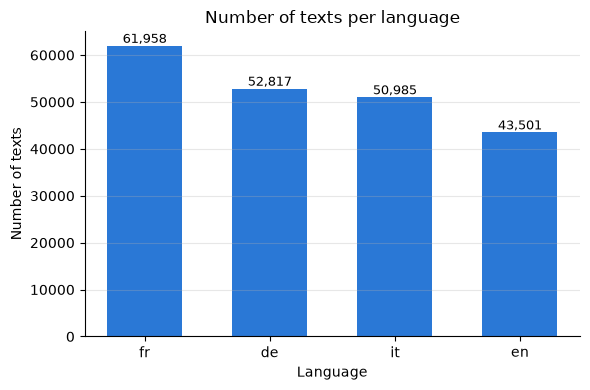

In [7]:
# Bar chart: one bar per language, sorted from largest to smallest
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(lang_counts.index, lang_counts.values, color=BLUE, width=0.6)

# Write the exact number above each bar so nobody has to read it off the axis
for x, y in zip(lang_counts.index, lang_counts.values):
    ax.text(x, y, f"{y:,}", ha="center", va="bottom", fontsize=9)

ax.set_title("Number of texts per language")
ax.set_xlabel("Language")
ax.set_ylabel("Number of texts")
plt.tight_layout()   # avoids cut-off labels
plt.show()

## 4. Text length (characters and words)

Real prompts can be short or long. Here we check how long the texts are – measured in characters and in words –
overall and per language.

In [8]:
# Number of characters per text: .str.len() counts the characters of every string
info["n_chars"] = df_gesamt["source_text"].str.len()

# Number of words per text: .str.split() cuts the text at spaces into a list of words,
# .str.len() then counts the elements of that list
info["n_words"] = df_gesamt["source_text"].str.split().str.len()

# .describe() gives count, mean, standard deviation, min, quartiles and max in one table
display(info[["n_chars", "n_words"]].describe().round(1))

,n_chars,n_words
count,209261.0,209261.0
mean,189.9,26.1
std,66.2,9.2
min,31.0,5.0
25%,145.0,20.0
50%,182.0,25.0
75%,227.0,31.0
max,2794.0,407.0


The histograms show how often each text length occurs (left: characters, right: words).

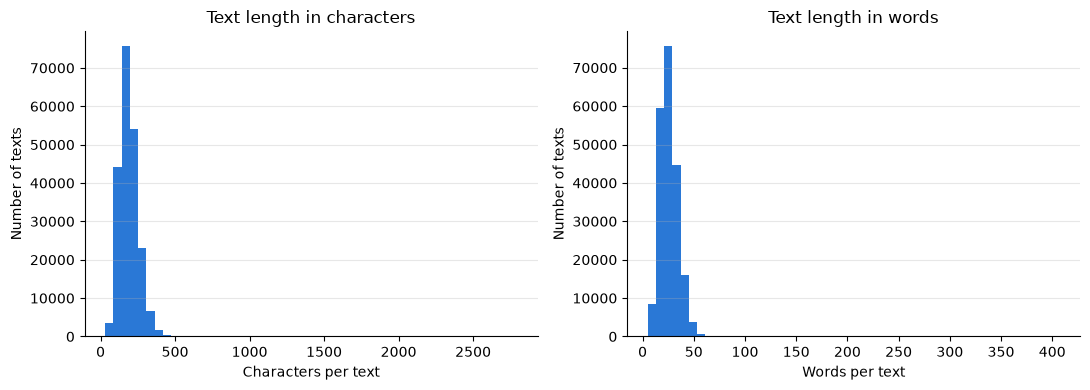

In [9]:
# Two charts next to each other: 1 row, 2 columns
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Histogram = the length range is split into 50 "bins" and we count how many texts fall into each bin
axes[0].hist(info["n_chars"], bins=50, color=BLUE)
axes[0].set_title("Text length in characters")
axes[0].set_xlabel("Characters per text")
axes[0].set_ylabel("Number of texts")

axes[1].hist(info["n_words"], bins=50, color=BLUE)
axes[1].set_title("Text length in words")
axes[1].set_xlabel("Words per text")
axes[1].set_ylabel("Number of texts")

plt.tight_layout()
plt.show()

Per language: the table shows the median (middle value) and mean, the boxplot shows the spread.
In the boxplot the box contains the middle 50 % of the texts, the line in the box is the median.

In [10]:
# groupby("language") splits the table into one group per language,
# .agg(...) then calculates median and mean for each group
length_per_lang = info.groupby("language")[["n_chars", "n_words"]].agg(["median", "mean"]).round(1)
display(length_per_lang)

n_chars        n_words      
          median   mean  median  mean
language                             
de         186.0  193.4    24.0  24.7
en         165.0  172.8    24.0  25.0
fr         191.0  198.1    27.0  28.0
it         184.0  191.0    25.0  26.3

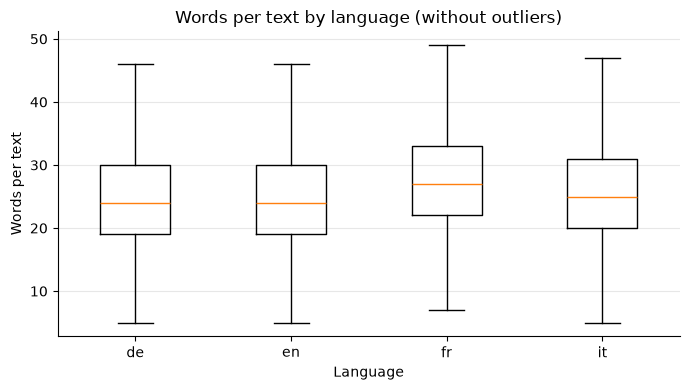

In [11]:
# Boxplot of the word count per language
languages = sorted(info["language"].unique())                        # e.g. ['de', 'en', 'fr', 'it']
data_per_lang = [info.loc[info["language"] == l, "n_words"] for l in languages]

fig, ax = plt.subplots(figsize=(7, 4))
# showfliers=False hides the single extreme outliers so the boxes stay readable
ax.boxplot(data_per_lang, tick_labels=languages, showfliers=False)
ax.set_title("Words per text by language (without outliers)")
ax.set_xlabel("Language")
ax.set_ylabel("Words per text")
plt.tight_layout()
plt.show()

## 5. PII labels: which types of personal data occur how often?

The column `privacy_mask` contains, for every text, a list of all PII entries with `value`, `start`, `end` and `label`.
We "unpack" these lists so that every single PII entry becomes its own row, and then count the labels.

In [12]:
import json

# Safety check: in some versions of the dataset privacy_mask is stored as a JSON *string*.
# If so, we convert it into a real Python list with json.loads. Otherwise we keep it as it is.
# (We store the result in a new variable – the raw data stays untouched.)
first_value = df_gesamt["privacy_mask"].iloc[0]
if isinstance(first_value, str):
    privacy_masks = df_gesamt["privacy_mask"].apply(json.loads)
    print("privacy_mask was a string -> parsed with json.loads")
else:
    privacy_masks = df_gesamt["privacy_mask"]
    print("privacy_mask is already a list -> no parsing needed")

# Example: what does one entry look like?
print("\nExample entry:", privacy_masks.iloc[0][0])

privacy_mask is already a list -> no parsing needed

Example entry: {'value': 'Northeast', 'start': 37, 'end': 46, 'label': 'ORDINALDIRECTION'}


In [13]:
# Build a "long" table: one row per PII entry instead of one row per text.
# .explode() turns a list [a, b, c] in one row into three separate rows.
pii = pd.DataFrame({"id": df_gesamt["id"], "language": df_gesamt["language"], "mask": privacy_masks})
pii = pii.explode("mask").dropna(subset=["mask"])   # dropna removes texts with an empty list

# Each entry is a dictionary like {"value": ..., "label": ...}; .str["label"] picks the label from it
pii["label"] = pii["mask"].str["label"]

print(f"Total number of PII entries: {len(pii):,}")
print(f"Number of different labels:  {pii['label'].nunique()}")

# How often does every label occur? (sorted from most to least frequent)
label_counts = pii["label"].value_counts()
display(label_counts.to_frame("count"))

Total number of PII entries: 649,462
Number of different labels:  56


,count
label,
FIRSTNAME,66766
LASTNAME,20976
DATE,19998
EMAIL,17968
PREFIX,13812
SEX,13528
JOBTYPE,13433
AMOUNT,13324
BUILDINGNUMBER,13311


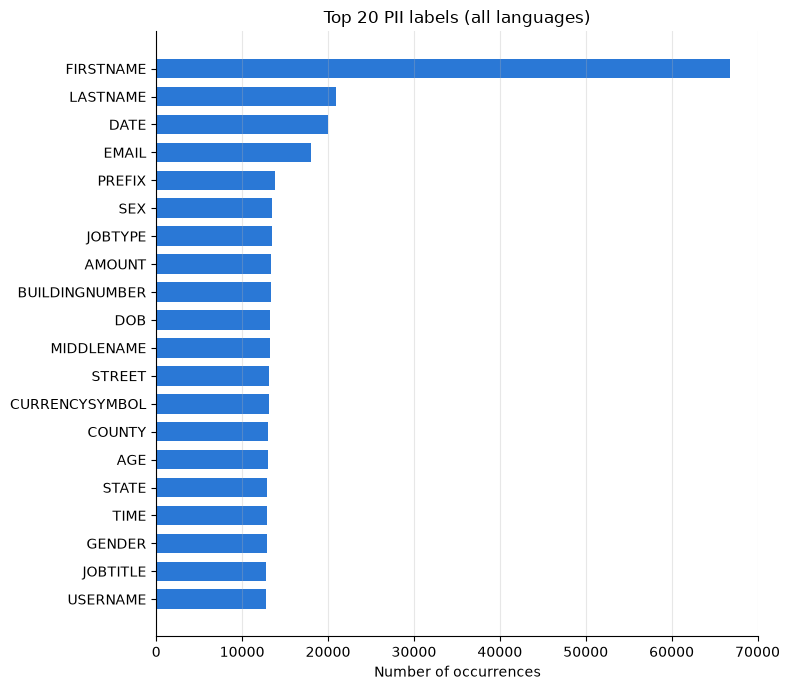

In [14]:
# Horizontal bar chart of the 20 most frequent labels
top20 = label_counts.head(20).sort_values()   # sort ascending so the largest bar ends up on top

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top20.index, top20.values, color=BLUE, height=0.7)
ax.set_title("Top 20 PII labels (all languages)")
ax.set_xlabel("Number of occurrences")
ax.grid(axis="x", alpha=0.3)   # vertical helper lines fit a horizontal bar chart better
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 6. Relevant PII types for our use case

Prompt Guard mainly cares about a few PII types. We group the dataset labels into five categories
and count **how many texts contain at least one** entity of that category – overall and for German only.

| Category | Dataset labels | Planned decision |
|---|---|---|
| IBAN | `IBAN` | block |
| Credit card | `CREDITCARDNUMBER` | block |
| Phone | `PHONENUMBER` | warn |
| E-mail | `EMAIL` | warn |
| Name | `FIRSTNAME`, `MIDDLENAME`, `LASTNAME` | warn |

In [15]:
# Our use-case categories and the dataset labels that belong to each of them
use_case_labels = {
    "IBAN":        ["IBAN"],
    "Credit card": ["CREDITCARDNUMBER"],
    "Phone":       ["PHONENUMBER"],
    "E-mail":      ["EMAIL"],
    "Name":        ["FIRSTNAME", "MIDDLENAME", "LASTNAME"],
}

# For every text: the set of labels it contains (a set removes repetitions, e.g. two FIRSTNAMEs)
labels_per_text = privacy_masks.apply(lambda mask: {entry["label"] for entry in mask})

# For every category add a True/False column to the helper table:
# True = the text contains at least one of the labels of this category
for category, labels in use_case_labels.items():
    info[category] = labels_per_text.apply(lambda s: len(s & set(labels)) > 0)  # & = intersection of two sets

categories = list(use_case_labels.keys())
is_german = info["language"] == "de"

# Summing True/False values counts the Trues (True = 1, False = 0); .mean() gives the share
use_case_table = pd.DataFrame({
    "texts (all)":   info[categories].sum(),
    "% (all)":       (info[categories].mean() * 100).round(1),
    "texts (de)":    info.loc[is_german, categories].sum(),
    "% (de)":        (info.loc[is_german, categories].mean() * 100).round(1),
})
display(use_case_table)

,texts (all),% (all),texts (de),% (de)
IBAN,9876,4.7,2524,4.8
Credit card,12612,6.0,3084,5.8
Phone,11744,5.6,3006,5.7
E-mail,17733,8.5,4389,8.3
Name,82819,39.6,21053,39.9


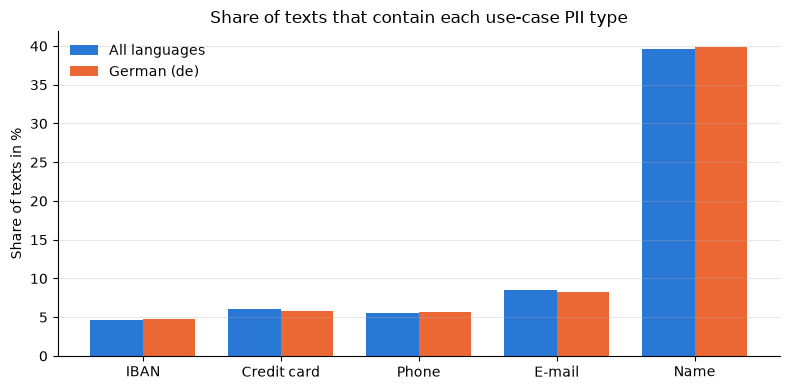

In [16]:
# Grouped bar chart: share of texts per category, all languages vs. German only.
# We compare percentages (not absolute numbers), because German is only a part of all texts.
x = range(len(categories))   # positions 0, 1, 2, ... for the categories on the x-axis
w = 0.38                     # width of one bar

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([i - w / 2 for i in x], use_case_table["% (all)"], width=w, color=BLUE, label="All languages")
ax.bar([i + w / 2 for i in x], use_case_table["% (de)"], width=w, color=ORANGE, label="German (de)")

ax.set_xticks(list(x))
ax.set_xticklabels(categories)
ax.set_ylabel("Share of texts in %")
ax.set_title("Share of texts that contain each use-case PII type")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

As a rough preview of the later decision logic: how many texts would contain **block**-relevant PII (IBAN or credit card)
and how many would contain at least one of our **warn** types?

In [17]:
# A text is "block-relevant" if it contains an IBAN OR (|) a credit card number
info["has_block_pii"] = info["IBAN"] | info["Credit card"]
# A text is "warn-relevant" if it contains a phone number OR an e-mail OR a name
info["has_warn_pii"] = info["Phone"] | info["E-mail"] | info["Name"]

print(f"Texts with block-relevant PII (IBAN/credit card): {info['has_block_pii'].sum():,} "
      f"({info['has_block_pii'].mean() * 100:.1f} %)")
print(f"Texts with warn-relevant PII (phone/e-mail/name): {info['has_warn_pii'].sum():,} "
      f"({info['has_warn_pii'].mean() * 100:.1f} %)")

Texts with block-relevant PII (IBAN/credit card): 21,783 (10.4 %)
Texts with warn-relevant PII (phone/e-mail/name): 95,086 (45.4 %)


## 7. Texts without any PII (examples for "allow")

For the decision **allow** the model must also see texts that contain no personal data at all.
We therefore count how many texts have an empty `privacy_mask` and how many PII entries a text usually has.

In [18]:
# Number of PII entries per text = length of the privacy_mask list
info["n_pii"] = privacy_masks.str.len()

n_no_pii = (info["n_pii"] == 0).sum()
print(f"Texts WITHOUT any PII: {n_no_pii:,} of {len(info):,} ({n_no_pii / len(info) * 100:.2f} %)")

# How many texts have 1, 2, 3, ... PII entries?
display(info["n_pii"].value_counts().sort_index().to_frame("number of texts").T)

Texts WITHOUT any PII: 0 of 209,261 (0.00 %)


n_pii,2,3,4,5,6,7,8,9,10,11,...,21,22,23,27,28,31,33,36,41,42
number of texts,87185,61958,32803,15606,6831,2647,1196,536,199,123,...,4,3,3,3,3,3,2,1,2,2


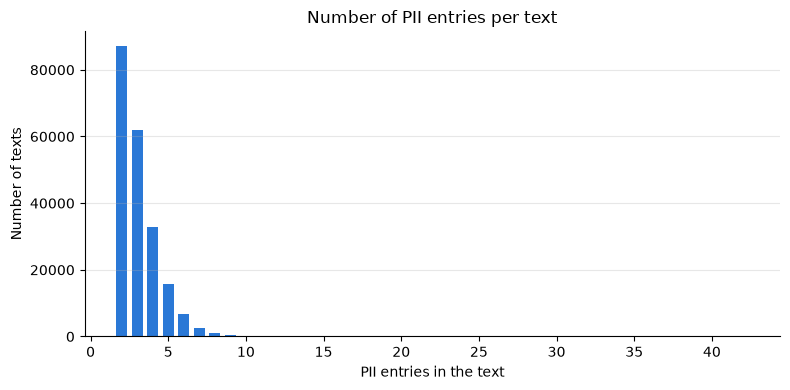

In [19]:
# Bar chart: distribution of the number of PII entries per text
pii_count_dist = info["n_pii"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(pii_count_dist.index, pii_count_dist.values, color=BLUE, width=0.7)
ax.set_title("Number of PII entries per text")
ax.set_xlabel("PII entries in the text")
ax.set_ylabel("Number of texts")
plt.tight_layout()
plt.show()

## 8. Three German example rows

To get a concrete idea of the data we look at three random German texts: the original text (`source_text`),
the masked version (`target_text`) and the list of found PII (`privacy_mask`).

In [20]:
# Show the full text in each cell instead of cutting it off with "..."
pd.set_option("display.max_colwidth", None)

# .sample(3, random_state=42) picks 3 random rows; the fixed random_state makes the
# selection reproducible, so everybody in the team sees the same three examples
examples = df_gesamt.loc[df_gesamt["language"] == "de", ["source_text", "target_text", "privacy_mask"]].sample(3, random_state=42)

# Print every example nicely, one PII entry per line
for i, (_, row) in enumerate(examples.iterrows(), start=1):
    print(f"=== Example {i} ===")
    print("source_text:", row["source_text"])
    print("target_text:", row["target_text"])
    print("privacy_mask:")
    for entry in row["privacy_mask"]:
        print(f"   {entry['label']:<20} -> {entry['value']!r}  (characters {entry['start']}-{entry['end']})")
    print()

# Reset the display option to the default value again
pd.reset_option("display.max_colwidth")

=== Example 1 ===
source_text: Der Konkurrent King - Hand hat einen neuen Krebsabsicherungsplan veröffentlicht. Bitte erstellen Sie eine Analyse für Norberto im Vergleich zu unserem, senden Sie diese per E-Mail an Hillary_Schaefer90@gmail.com, sobald Sie fertig sind.
target_text: Der Konkurrent [COMPANYNAME] hat einen neuen Krebsabsicherungsplan veröffentlicht. Bitte erstellen Sie eine Analyse für [FIRSTNAME] im Vergleich zu unserem, senden Sie diese per E-Mail an [EMAIL], sobald Sie fertig sind.
privacy_mask:
   COMPANYNAME          -> 'King - Hand'  (characters 15-26)
   FIRSTNAME            -> 'Norberto'  (characters 118-126)
   EMAIL                -> 'Hillary_Schaefer90@gmail.com'  (characters 183-211)

=== Example 2 ===
source_text: Hallo Vinnie, wir haben eine unregelmäßige Transaktion von dieser digitalen Geldbörse 1AgVuqZPn2kLHfUDC1XLQQNDxQu auf Ihr Konto 62374974 bemerkt. Bestätigen Sie Ihre Transaktion.
target_text: Hallo [FIRSTNAME], wir haben eine unregelmäßige Transaktion

## 9. Conclusion: does the dataset fit Prompt Guard?

**What speaks for the dataset**
- **Large and clean:** ~209k texts, no missing values, no duplicate IDs (only 1 duplicate text).
- **German is well covered:** ~52.8k German texts (25 %), the languages are roughly balanced.
- **All our key PII types are present:** names (~40 % of texts), e-mail (~8 %), credit card (~6 %), phone (~6 %), IBAN (~5 %) – with similar shares in German.
- **Ready for NER:** character positions (`privacy_mask`) and word-level BIO labels (`mbert_bio_labels`) are already included.
- **Prompt-like length:** typically 1–2 sentences (median ~25 words), which is similar to short real prompts.

**What is missing or noticeable**
- **No texts without PII at all** – every text has at least 2 PII entries. For the decision *allow* we must add PII-free texts ourselves (e.g. from another dataset or self-written prompts).
- **Class imbalance:** `FIRSTNAME` is ~3× more frequent than most other labels, while some block-relevant labels such as `IBAN`, `BIC` or `CREDITCARDCVV` are much rarer. Inside a text, most words are labelled "O" (no PII), so the imbalance on word level is even stronger.
- **Many labels (56) for few decisions (3):** we should map the labels to our categories (block / warn / irrelevant) before training.
- **Synthetic data:** the texts are generated – e.g. German texts often contain English names, phone numbers in random international formats or English words like "Northeast". Only ~1.5 % of the IBANs in the German texts start with `DE` (IBANs from all countries are mixed). Real German prompts may look different, so we should test on a few realistic examples.
- **Only a `train` split:** the column `set` contains only "train", so we must create our own train / validation / test split.

**Overall:** the dataset is a good basis for training the NER model, but it must be complemented with PII-free examples for *allow* and checked against realistic German prompts.